In [6]:
import pandas as pd 
import nltk
link="S:\\ML\\Kaggle_dataset\\diabetes_risk_prediction_dataset.csv"
df=pd.read_csv(link)
dataset=df.drop(columns=["Patient_ID"])
dataset

,Age,Gender,Country,Height_cm,Weight_kg,BMI,Waist_Circumference_cm,Blood_Glucose,HbA1c,Fasting_Blood_Sugar,...,Fatty_Liver,PCOS,Medication_Adherence,Work_Type,Residence_Type,Daily_Water_Intake_L,Diabetes_Risk_Score,AI_Health_Recommendation,Doctor_Consultation_Needed,Diabetes_Risk
0,32.0,Male,Mexico,182.1,65.8,19.8,71.2,88.4,10.4,149.5,...,Yes,No,Good,Retired,Rural,4.4,60,Healthy Diet Plan,Yes,Moderate
1,42.0,Other,Saudi Arabia,148.5,101.2,45.9,121.8,247.3,11.3,199.3,...,Yes,Yes,Average,Government,Rural,2.1,99,Begin Diabetes Management Plan,Yes,High
2,89.0,Other,Argentina,158.1,NaN,37.9,131.8,141.9,6.3,219.6,...,Yes,No,Average,Government,Urban,2.8,80,Strict Blood Sugar Monitoring,Yes,High
3,87.0,Other,United States,190.9,95.9,26.3,99.1,90.1,7.4,217.7,...,No,No,Average,Business,Rural,1.5,82,Begin Diabetes Management Plan,Yes,High
4,27.0,Other,Australia,156.9,101.9,41.4,77.1,93.8,12.0,153.5,...,Yes,Yes,Poor,Private,Rural,1.6,93,Begin Diabetes Management Plan,Yes,High
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,52.0,Female,United Kingdom,153.9,107.4,45.3,75.9,248.8,9.9,191.5,...,No,Yes,Average,Retired,Urban,3.5,86,Consult Endocrinologist Immediately,Yes,High
49996,53.0,Male,United Kingdom,179.6,64.0,19.8,114.5,198.4,6.3,110.0,...,Yes,No,Average,Government,Urban,3.4,49,Weight Management Program,No,Moderate
49997,88.0,Male,Brazil,194.1,65.6,17.4,96.1,118.8,NaN,208.4,...,Yes,Yes,Poor,Retired,Urban,2.6,100,Begin Diabetes Management Plan,Yes,High
49998,23.0,Other,Bangladesh,168.0,73.9,26.2,131.4,139.5,9.2,84.7,...,Yes,Yes,Good,Private,Urban,2.7,52,Increase Physical Activity,No,Moderate


In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer as feed
from scipy.sparse import hstack
vectorize=feed()
x1=vectorize.fit_transform(dataset["AI_Health_Recommendation"])
x2=vectorize.fit_transform(dataset["Gender"])
x3=vectorize.fit_transform(dataset["Country"])
x4=vectorize.fit_transform(dataset["Diet_Quality"])
x5=vectorize.fit_transform(dataset["Sugar_Intake_Level"])
x6=vectorize.fit_transform(dataset["Stress_Level"])
x7=dataset.drop(columns=["AI_Health_Recommendation","Gender","Country","Diet_Quality","Sugar_Intake_Level","Stress_Level","Physical_Activity_Level","Smoking_Status","Alcohol_Consumption","Family_History_Diabetes","Doctor_Consultation_Needed","Diabetes_Risk_Score","Diabetes_Risk","Hypertension","Heart_Disease","Fatty_Liver","PCOS","Medication_Adherence","Work_Type","Residence_Type"])
y=dataset[["Doctor_Consultation_Needed","Diabetes_Risk"]]
y

,Doctor_Consultation_Needed,Diabetes_Risk
0,Yes,Moderate
1,Yes,High
2,Yes,High
3,Yes,High
4,Yes,High
...,...,...
49995,Yes,High
49996,No,Moderate
49997,Yes,High
49998,No,Moderate


NOW WE NEED TO COMBINE ALL VALUES OF X WITH hstack

In [8]:
from sklearn.impute import SimpleImputer 
cleaner=SimpleImputer()
x7=cleaner.fit_transform(x7)
x=hstack([x1,x2,x3,x4,x5,x6,x7])
from sklearn.model_selection import train_test_split as ttp
x_train,x_test,y_train,y_test=ttp(x,y,test_size=0.25,random_state=19, shuffle=True)
from sklearn.tree import DecisionTreeClassifier as DtC
classify=DtC()
classify.fit(x_train,y_train)
y_pred= classify.predict(x_test)

In [9]:
from sklearn.metrics import accuracy_score 
from sklearn.metrics import ConfusionMatrixDisplay
score1=accuracy_score(y_test["Doctor_Consultation_Needed"],y_pred[:,0])
score2=accuracy_score(y_test["Diabetes_Risk"],y_pred[:,1])
score=((score1+score2)/2)*100
score

94.96

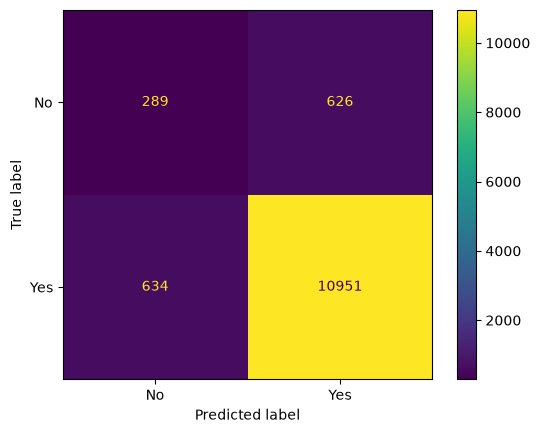

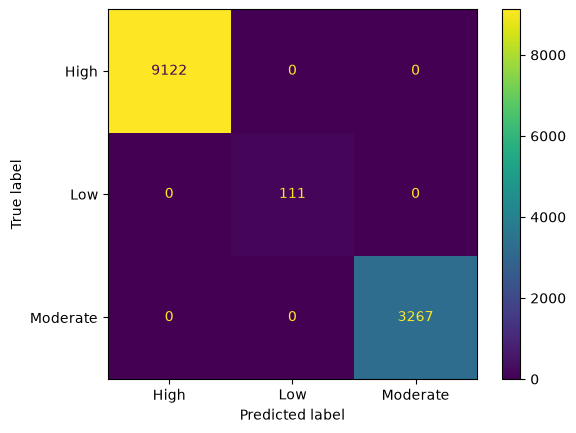

In [10]:
ConfusionMatrixDisplay.from_predictions(y_test["Doctor_Consultation_Needed"],y_pred[:,0])
ConfusionMatrixDisplay.from_predictions(y_test["Diabetes_Risk"],y_pred[:,1])